In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/EC_Classification/AUG',
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 1074 files belonging to 3 classes.


In [5]:
class_names = dataset.class_names

In [6]:
def flatten_dataset(dataset):
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')
            img_flattened = img_array.flatten()
            flat_data.append(img_flattened)
            target_data.append(label.numpy())
    return np.array(flat_data), np.array(target_data)

In [7]:
train_size = int(0.85 * len(dataset))
test_size = int(0.15 * len(dataset))

In [8]:
train_ds = dataset.take(train_size)
test_ds = dataset.skip(train_size).take(test_size)

In [9]:
x_train, y_train = flatten_dataset(train_ds)
x_test, y_test = flatten_dataset(test_ds)

In [10]:
# Creating a support vector classifier
svc=SVC(probability=True, random_state=72)

In [10]:
svc.fit(x_train,y_train)

SVC(C=1.0, break_ties=False, cache_size=200, class_weight=None, coef0=0.0,
    decision_function_shape='ovr', degree=3, gamma='scale', kernel='rbf',
    max_iter=-1, probability=True, random_state=72, shrinking=True, tol=0.001,
    verbose=False)

In [11]:
y_pred = svc.predict(x_test)

In [14]:
accuracy = accuracy_score(y_test, y_pred)
print("The model is {:.2f}% accurate".format(accuracy * 100))

The model is 79.38% accurate


In [16]:
from sklearn.metrics import classification_report

print("Validation metrics for Normal Random Forest:")
print(classification_report(y_true=y_test, y_pred=y_pred, target_names=class_names))

Validation metrics for Normal Random Forest:
              precision    recall  f1-score   support

   Dysplasia       0.73      0.88      0.80        56
      Normal       0.83      0.73      0.78        48
         SCC       0.84      0.77      0.80        56

    accuracy                           0.79       160
   macro avg       0.80      0.79      0.79       160
weighted avg       0.80      0.79      0.79       160



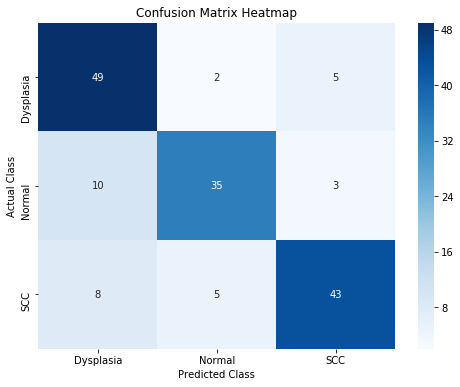

In [17]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [19]:
import joblib

# Assuming 'svc' is your trained model
joblib_file = '/home/smartcity_sp7/EC_Classification/Saved Models/svm_model(WLI).joblib'
joblib.dump(svc, joblib_file)

['/home/smartcity_sp7/EC_Classification/Saved Models/svm_model(WLI).joblib']

In [11]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

In [ ]:
param_grid = {'C': [0.1, 1, 10, 100],
              'gamma': ['scale', 'auto'],
              'kernel': ['rbf', 'linear', 'poly', 'sigmoid']}

In [ ]:
grid_search = GridSearchCV(estimator=svc, param_grid=param_grid, cv=StratifiedKFold(n_splits=2))

In [ ]:
grid_search.fit(x_train, y_train)

In [ ]:
best_model = grid_search.best_estimator_
y_pred1 = best_model.predict(x_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred1)
print("The model is {:.2f}% accurate".format(accuracy * 100))

In [ ]:
from sklearn.metrics import classification_report

print("Validation metrics for SVM with Hyperparameter Tuning:")
print(classification_report(y_true=y_test, y_pred=y_pred1, target_names=class_names))

In [ ]:
cm = confusion_matrix(y_test, y_pred1)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()